# Reliability metrics and analytic calculation
*Jan Ringelstein*

This notebook summarizes basic ideas for reliability metrics and introduces simple analytical reliability calculation in pandaict. The basic datamodel features three parameters that relate to reliability: Mean Time Between Failure (MTBF), Mean Time To Repair (MTTR) and Bit Error Rate (ber). This was motivated by the original pandaict code. 

The parameters apply to physical-layer elements. The following table shows which element has which parameter.

| Element Type | MTBF | MTTR | ber |
|---|---|---|---|
|node| X | X | X |
|device| X | X | |
|link*| X | X | X* |

(*) For links, the parameters are given through the linktype. The ber is given as bit error rate per kilometer, where the link length is defined in the individual link parameter set. 


The question now is how to calculate meaningful reliability metrics on connection level, taking all elements along the physical route into account, while also respecting the routing algorithm. pandaict basically supports two methods for this: 

1. Analytic calculation or
2.  Monte-Carlo simulation

As the Monte-Carlo simulation is covered in other notebooks, the remainder of this notebook is about the analytic calculation method. Reliability block diagrams are useful for investigating this. 

# MTBF and MTTR for interconnected systems

Generally, pandaict networks consist of elements with individal MTBF and MTTR that are interconnedted. First of all, the terms are defined as such: 

- MTTR is the mean time to repair an element after a failure occured. This includes failure detection, diagnosis, repair and bringing back online.
- MTTF (which is sometimes used) is the mean time an element runs after repair until it fails. 
- MTBF is the mean time between occurence of element failures. Following the definitions, MTBF = MTTF + MTTR.
- Availability (A) is the mean ratio between an element's or system uptime and total time (which is uptime+downtime).
- Reliability (R) according to [5, 2.5 and 2.6] can be specified in various ways, e.g. using the MTBF

Notably, MTTF and MTBF are only relevant for elements that are repairable [5], which we generally assume to be the case for ICT network components. 
Also, it's sufficient to consider two paramaters of the set [MTTR, MTTF, MTBF] because the third can be calculated from any two. 
Availability on the other hand, using the definitions above, can be expressed in different ways: 

$$
    A = \frac{MTTF}{MTBF}=\frac{MTBF-MTTR}{MTBF}=\frac{MTTF}{MTTF+MTTR}
$$

We'll work with MTBF and MTTR from here on. Now, how can those be calculated for the whole system? Researching this shows that such calculation is different for serial and parallel systems, and different sources give different formula. For serial systems, the German Wikipedia page [1] gives a formula different from the English version [2] as well as Aurora Cons. [3] and Legrand [4]. For systems with parallel elements or subsystems, the calculation depends on how many of them need to fail for the whole system to fail. Most often looked at is the case that all parallel elements or subsystems have to fail for that. For this, the German Wiki [1] gives a different formula than the English one [2] and Aurora [3], while Legrand [4] again gives another one. [5] on the other hand is the most concise source and calculates system MTBF and MTTR using reliability and availability. 

*Note*: The German Wiki apparently suffers from using MTBF when in fact they mean MTTF, while the English Wiki [2] seems to be consistent with Aurora [3]. Still, [5] is most the concise of these sources. 

According to [5], the main characteristics for reliability is that it degrades over time: a system that can fail is increasingly likely to do so as time goes by. This is expressed by the function: 

$$
    R(t) = e ^ {-\lambda t}
$$

.. where $R(t)$ is the time-dependent reliability, and $\lambda$ is a measure for the degradation speed. [5] calls $\lambda$  "failure rate". In case of repairable systems, it would seem that the usual relation between R, \lambda and MTBF is: 

$$
    MTBF = \int_0^\infty e ^ {-\lambda t} dt = \frac{1}{\lambda}
$$

These definitions are consistently used by [2],[3] and [4]. Hence the formula for serial MTBF according to [5] matches [2] and [4]. For parallel systems, [5] does not give a well-useable formula but [2] and [4] do (their formula are consistent, too). For serial MTTR, the same is the case. For parallel MTTR, all three sources are again consistent. 


This yields the following useable formula:

## Serial system

![grafik.png](images/3d6492a6-6455-4cba-9a4f-5a8fc86f3887.png)


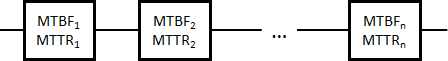

$$
    MTBF_{serial} = \Bigg( \sum \limits_{i=1} ^ {n} \frac{1}{MTBF_{i}} \Bigg) ^{-1}
$$

For n=2: 

$$
    MTBF_{serial} = \frac{MTBF_{1} MTBF_{2}}{MTBF_{1} + MTBF_{2}}
$$
$$
    MTTR_{serial} = \frac{MTBF_{1} MTTR_{2} + MTBF_{2} MTTR_{1}}{MTBF_{1} + MTBF_{2}}
$$
$$
    A_{serial} = A_{1} A_{2}
$$

## Parallel system

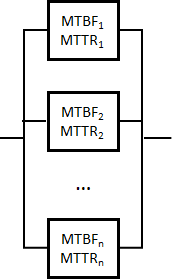

For n=2: 

$$
    MTBF_{parallel} = \frac{MTBF_{1} MTBF_{2}}{MTTR_{1} + MTTR_{2}}
$$
$$
    MTTR_{parallel} = \frac{MTTR_{1} MTTR_{2}}{MTTR_{1} + MTTR_{2}}
$$
$$
    A_{parallel} = A_{1} + A_{2} - A_{1} A_{2}
$$

And in general: 

$$
    MTTR_{parallel} = \Bigg( \sum \limits_{i=1} ^{n} \frac{1}{MTTR_{i}} \Bigg) ^ {-1}
$$

## Systems with more than 2 components and mixed systems

Note that there are formula for systems with more than 2 components for all values, but in some cases this gets complicated. However, one can always apply the formula for 2-component systems iteratively, hence calculate any system with n components (even if this might not be the fastest way). Also note that the availability can always be calculated using MTBF and MTTR as stated further above. 

Mixed systems according to [5] may be split up into basic parallel or serial systems, thus be calculated iteratively. However, this can become complex in some cases (cp. [5], chapter 5.6). 


# Application to pandaict

How can we apply the learnings so far to a pandaict network? 
Considering a single connection and a specific communication direction (down- or upstream), multiple paths might be on the route between communication peers. Link usage probability (LUP) tables express the available routes for a connection, and state which percentage of information items take them, which depends on the routing algorithm selected. In this case, one might draw a reliability block diagram that looks somewhat like this (where the end device might be replaced by a CONVERTER-type communication node):

![grafik.png](images/304c0b71-db73-4554-97e0-119819268020.png)

Note that the nodes shown here might not be unique, i.e. the same node might appear in different routes. p1 ... pr denote the probabilities with which information items take one of the routes 1..r. The nodes are not given in the LUP tables, but can be easily calculated by traversing the links along the route. 

Now, this looks like we generally have a mixed system consisting of serial subcomponents (the routes) that are connected in parallel. However, the graph is flawed because some nodes in there might re-appear in multiple routes. The real ICT network might be much more complex, and can not be depicted in this way. However, there is one exception to this: **if each information item uses exactly one route, i.e. information items are **not** copied within the network, parallel subsystem connections do not play out**. Instead, the total MTTR and MTBF are a combination of the serial MTTR and MTBF. This is the case for most routing algorithms (shortest-path, random, lowest-loading, round-robin). 

Hence it seems to make sense to implement our calculations for this case, which we call "single-path / no-copy routing". 
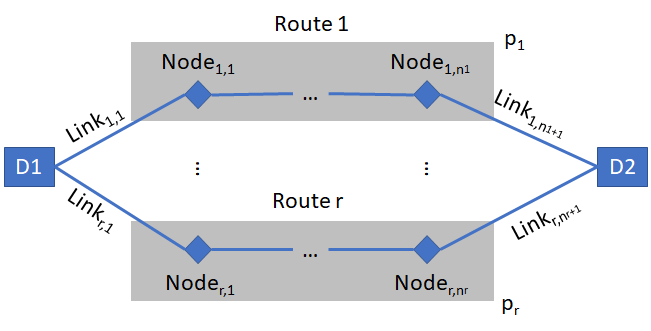

# Total MTBF, MTTR and availability for single-path / no-copy routing

With reference to the last graphic above, the LUP table for given connection contains the possible routes $1..r$, the involved links $Link_{1,1}..Link_{r,lr}$ as well as the probabilities with which an information item takes one of the routes $p_{1}..p_{r}$. The nodes $Node_{1,1}..Node_{r,lr}$ are not directly given in the LUP table but need to be determined by traversing the links. A neccessary prerequisite to the caluclation is 

$$
    \sum \limits_{i=1} ^ r p_{i} <= 1    
$$ 

This means that information items must not be sent over multiple routes. In other words, if information items are copied in the network and sent over multiple routes (as e.g. when using flooding), the calculation method is inappropriate. 

Let $MTBF_{i,j} ^{link}$ and $MTTR_{i,j} ^{link}$ be the MTBF and MTTR for the link $(i,j)$ and $MTBF_{i,j} ^{node}$ and $MTTR_{i,j} ^{node}$ the MTBF and MTTR for the node $(i,j)$, as stored in the link types resp. node data. Using this, the total MTBF and MTTR values are calculated as follows. 

## Total MTBF

The total MTBF is calculated as: 

$$
    MTBF_{r} ^{route} = \Bigg( \sum \limits_{i=1} ^ {n_{r}+1} \frac{1}{MTBF_{r,i} ^ {link}} + \sum \limits_{i=1} ^ {n_{r}} \frac{1}{MTBF_{r,i} ^ {node}}\Bigg ) ^ {-1}
$$
$$
    MTBF ^{total} = \sum \limits_{i=1} ^ {r} p_i MTBF_{i} ^{route}
$$

Reasoning: 
Generally, MTBF is the ratio between a time and the number of system failures within that time. For example, let's assume that a network is operated 1000 hours and 100 information items per hour are constantly sent. If there are two possible routes with $p_1 = 40%$ and $p_2 = 60%$, 40.000 items take route 1 and 60.000 items take route 2. But one could also say that routes 1 and 2 are used for information transmission for 400 resp. 600 hours, with a constant rate for information items per time. The MTBF of the individual routes are calculated using the formula for serial systems, where both link and node MTBFs are taken into account. Let's say that $MTBF_1 ^ {route} = 10h$ and $MTBF_2 ^ {route} = 20h$. Hence, within the 400 h route 1 is used, we see 40 failures and from the 600 h route 2 is used, 30 failures. So the total failure number is 70 within a total time of 1000 hours. Hence the total MTBF is $\frac{1000 h}{70} = 14.3 hours$. One can see that the route MTBFs have to be added using the probabilities as weights. 

## Total MTTR

The MTTR for a serial system can only be determined iteratively by splitting up the system into subsystems that contain component pairs. Also, the MTBF is needed for this, which also needs to be calculated iteratively.  so the calculation is a bit more complex:

Initial value: 

$$
    MTBF_r ^{route}(1) = \frac{MTBF_{r,1} ^{link} MTBF_{r,1} ^{node}}{MTBF_{r,1} ^{link} + MTBF_{r,1} ^{node}}
$$

$$
    MTTR_r ^{route}(1) = \frac{MTBF_{r,1} ^{link} MTTR_{r,1} ^{node} + MTBF_{r,1} ^{node} MTTR_{r,1} ^{link}}{MTBF_{r,1} ^{link} + MTBF_{r,1} ^{node}}
$$

The MTBF and MTTR now need to be updated for each link and node. For each iteration $i=(2..n_{r}+1)$, we first calculate a "helper" MTBF and MTTR that includes the next link:

$$
    MTBF_H = \frac{MTBF_r ^{route}(i-1) MTBF_{r,i} ^{link}}{MTBF_r ^{route}(i-1) + MTBF_{r,i} ^{link}}
$$

$$
    MTTR_H = \frac{MTBF_r ^{route} MTTR_{r,l} ^{link} + MTBF_{r,l} ^{link} MTTR_r ^{route}}{MTBF_r ^{route} + MTBF_{r,l} ^{link}} 
$$

In case of the last iteration $i=n_{r}+1$, these helper values are alreday the final results for $MTBF_r ^{route}$ and  $MTTR_r ^{route}$. Otherwise, we calculate the values to be used for the next iteration by adding the next node:

$$
    MTBF_r ^{route}(i) = \frac{MTBF_H MTBF_{r,i} ^{node}}{MTBF_H + MTBF_{r,i} ^{node}}
$$

$$
    MTTR_r ^{route}(i) = \frac{MTBF_H MTTR_{r,i} ^{node} + MTBF_{r,i} ^{node} MTTR_H}{MTBF_H + MTBF_{r,i} ^{node}}
$$

The resulting $MTTR_r ^{route}$ are used to calculate the total:  

$$
    MTTR ^{total} = \sum \limits_{i=1} ^ {i} p_i MTTR_i ^{route}
$$

Of course, if MTTR and MTBF should both be calculated, this iterative approach can also be used to calculate MTBF in the same fashion:

$$
    MTBF ^{total} = \sum \limits_{i=1} ^ {r} p_i MTBF_i ^{route}
$$

The reasoning for weighting the route MTBF and MTTR with the probabilities is that generally, the total number of information items transmitted and the total time of consideration may be split up between the different routes according to probabilities, and both MTTR and MTBF on the level of routes behave linear with regards to the total system (cp. reasoning for MTBF above). As pointed out before, this only works as long as each information item takes exactly one and only one route. 



# Availability

Availability for the total system is easiest calculated as:

$$
    Avail_{total} = \frac{MTBF_{total}}{MTBF_{total}+MTTR_{total}}
$$

# Bit error rate 

For the bit error rate, for a route r serial system with $ n_r $ elements (nodes and/or links) that have individual bit error rates $ ber_{r,i} $, we use: 

$$
    ber ^{route}_r = 1 - \prod \limits_{i=1} ^ {n_r} (1-ber_{r,i}) 
$$

And the total ber is straightforward: 

$$
    ber ^{total} = \sum \limits_{i=1} ^ {r} p_i ber ^{route}_i
$$




# Literature 

[1] Wikipedia (dt.): MTBF und Verfügbarkeit zusammengesetzter Systeme, Online: https://de.wikipedia.org/wiki/Mean_Time_Between_Failures (Aug 2024)

[2] Wikipedia (engl.): Mean time between failures, Online: https://en.wikipedia.org/wiki/Mean_time_between_failures (Aug 2024)

[3] Legrand: Reliability and Availability in Legrand UPS, white paper

[4] Don L. Lin (Aurora Consulting Engineering LLC): Reliability Characteristics for Two Subsystems in Series or Parallel or n Subsystems in m_out_of_n Arrangement

[5] Savety and Reliability Society: Applied R&M Manual for Defence Systems, Part D - Supporting Theory, Chapter 6 - probabilistic R&M parameters and redundancy caluclations

[6] W. Ahmad, O. Hasan, U. Pervez, and J. Quadir: Reliability Modeling and Analysis of Communication Networks, Journ. of Network and Computer Applications, Vol. 78, 2017, pp. 191-215